# Домашнее задание по теме «Базовые принципы ML и метрики регрессии»

Это первое домашнее задание на курсе по ML.

<!-- Повторим ключевые особенности, о которых стоит помнить (со многими из них ты уже сталкивался в рамках курса "Искуственный интеллект"): -->




Важно помнить:
* За каждую задачу ты получаешь баллы.
* Сумма баллов за все задания — 12.
Максимальный балл за домашнее задание — 10. Разница в 2 балла позволит выбирать задачи или решить все, но получить максимальный балл даже в случае ошибки.
* В заданиях будут подсказки, инструкции и дополнительная теория, которая поможет по-новому посмотреть на тему.
* Условия задач — это техническое задание для разработчика, которому надо точно следовать.



## Импорт библиотек

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

## Загрузка данных

In [ ]:
!gdown 13vRyN_RKtoUWtGWi0O8ZlP5Q2C0O0F9l

Downloading...
From: https://drive.google.com/uc?id=13vRyN_RKtoUWtGWi0O8ZlP5Q2C0O0F9l
To: /content/store_sharing.csv
100% 1.03M/1.03M [00:00<00:00, 132MB/s]


Дальше ты будешь работать с датасетом, который содержит данные по аренде велосипедов. Ниже подробно описаны его признаки.

In [ ]:
bike = pd.read_csv('/content/store_sharing.csv')
bike.head()

,timestamp,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season
0,2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,3.0,0.0,1.0,3.0
1,2015-01-04 01:00:00,138,3.0,2.5,93.0,5.0,1.0,0.0,1.0,3.0
2,2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,1.0,0.0,1.0,3.0
3,2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,1.0,0.0,1.0,3.0
4,2015-01-04 04:00:00,47,2.0,0.0,93.0,6.5,1.0,0.0,1.0,3.0


**Признаки**

* `timestamp` — временная метка, используется для группировки данных по времени.
* `cnt` — общее количество новых аренд велосипедов (bike shares) за период между текущим и следующим `timestamp`. Обрати внимание, что это целевая переменная задачи регрессии.
* `t1` — фактическая температура воздуха (в градусах Цельсия).
* `t2` — температура «по ощущениям» (в градусах Цельсия); учитывает влияние ветра и влажности.
* `hum` — относительная влажность воздуха в процентах.
* `wind_speed` — скорость ветра (в километрах в час).
* `weather_code` — категориальный признак, описывающий погодные условия:
 * 1 — ясно;
 * 2 — рассеянная облачность / немного облаков;
 * 3 — переменная облачность (частично закрыто облаками);
 * 4 — пасмурно;
 * 7 — дождь / слабый ливень / мелкий дождь;
 * 10 — дождь с грозой;
 * 26 — снегопад;
 * 94 — туман / морозный туман.

* `is_holiday` — логический признак: 1 — праздничный день, 0 — обычный день.
* `is_weekend` — логический признак: 1 — выходной день (суббота или воскресенье), 0 — будний день.
* `season` — категориальный признак, обозначающий время года:
 * 0 — весна;
 * 1 — лето;
 * 2 — осень;
 * 3 — зима.



## Предобработка данных

Посмотрим на данные.

In [ ]:
bike.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17414 entries, 0 to 17413
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   timestamp     17414 non-null  object 
 1   cnt           17414 non-null  int64  
 2   t1            17414 non-null  float64
 3   t2            17414 non-null  float64
 4   hum           17414 non-null  float64
 5   wind_speed    17414 non-null  float64
 6   weather_code  17414 non-null  float64
 7   is_holiday    17414 non-null  float64
 8   is_weekend    17414 non-null  float64
 9   season        17414 non-null  float64
dtypes: float64(8), int64(1), object(1)
memory usage: 1.3+ MB


In [ ]:
bike.columns

Index(['timestamp', 'cnt', 't1', 't2', 'hum', 'wind_speed', 'weather_code',
       'is_holiday', 'is_weekend', 'season'],
      dtype='object')

In [ ]:
bike.describe().T

,count,mean,std,min,25%,50%,75%,max
cnt,17414.0,1143.101642,1085.108068,0.0,257.0,844.0,1671.75,7860.0
t1,17414.0,12.468091,5.571818,-1.5,8.0,12.5,16.00,34.0
t2,17414.0,11.520836,6.615145,-6.0,6.0,12.5,16.00,34.0
hum,17414.0,72.324954,14.313186,20.5,63.0,74.5,83.00,100.0
wind_speed,17414.0,15.913063,7.894570,0.0,10.0,15.0,20.50,56.5
weather_code,17414.0,2.722752,2.341163,1.0,1.0,2.0,3.00,26.0
is_holiday,17414.0,0.022051,0.146854,0.0,0.0,0.0,0.00,1.0
is_weekend,17414.0,0.285403,0.451619,0.0,0.0,0.0,1.00,1.0
season,17414.0,1.492075,1.118911,0.0,0.0,1.0,2.00,3.0


In [ ]:
# Есть ли дубли в строках

duplicate_rows = bike.duplicated().sum()
if duplicate_rows > 0:
    print("\nКоличество дублирующихся строк:", duplicate_rows)
    print("Дубли:")
    print(df[df.duplicated()])
else:
    print("\nДублирующиеся строки отсутствуют.")


Дублирующиеся строки отсутствуют.


In [ ]:
# Есть ли пропущенные значения

bike.isnull().sum()

,0
timestamp,0
cnt,0
t1,0
t2,0
hum,0
wind_speed,0
weather_code,0
is_holiday,0
is_weekend,0
season,0


Проведём небольшую предобработку для более удобной работы с данными.

In [ ]:
# Переименуем некоторые столбцы

bike.rename(columns={'cnt':'total_count', 't1':'temp', 't2':'feel_temp', 'hum':'humidity'}, inplace=True)
bike.columns

Index(['timestamp', 'total_count', 'temp', 'feel_temp', 'humidity',
       'wind_speed', 'weather_code', 'is_holiday', 'is_weekend', 'season'],
      dtype='object')

In [ ]:
# Разделим дату и время из столбца timestamp на несколько отдельных признаков, а именно:
# год, месяц, день, день недели (номер), час

bike.timestamp = pd.to_datetime(bike.timestamp)

bike['year'] = pd.to_datetime(bike['timestamp'], format='%d/%m/%Y').dt.year
bike['month'] = pd.to_datetime(bike['timestamp'], format='%d/%m/%Y').dt.month
bike['day'] = pd.to_datetime(bike['timestamp'], format='%d/%m/%Y').dt.day
bike['day_of_week'] = pd.to_datetime(bike['timestamp'], format='%d/%m/%Y').dt.dayofweek
bike['hour'] = pd.to_datetime(bike['timestamp'], format='%d/%m/%Y').dt.hour

In [ ]:
bike.head()

,timestamp,total_count,temp,feel_temp,humidity,wind_speed,weather_code,is_holiday,is_weekend,season,year,month,day,day_of_week,hour
0,2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,3.0,0.0,1.0,3.0,2015,1,4,6,0
1,2015-01-04 01:00:00,138,3.0,2.5,93.0,5.0,1.0,0.0,1.0,3.0,2015,1,4,6,1
2,2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,1.0,0.0,1.0,3.0,2015,1,4,6,2
3,2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,1.0,0.0,1.0,3.0,2015,1,4,6,3
4,2015-01-04 04:00:00,47,2.0,0.0,93.0,6.5,1.0,0.0,1.0,3.0,2015,1,4,6,4


Дальше ты будешь строить графики и делать по ним выводы. К первым задачам вывод уже написан — это поможет тебе понять, как их писать.

## Задача 1 [1 балл]

Для начала построй два графика.

1. Построй гистограмму распределения общего количества арендованных велосипедов (`total_count`) с наложенной линией KDE (Kernel Density Estimate), чтобы визуально оценить форму распределения данных. Оформи график с понятным заголовком и подписями осей. **[0,5 балла]**
  > **Примечание.** К этому графику вывод уже написан — ты найдёшь его ниже.
2. Преобразуй столбец `timestamp` к формату даты без времени (`date`). Объедини данные о прокате велосипедов по дням, посчитав суммарное количество арендованных велосипедов за каждый день. Построй линейный график с динамикой суточного числа аренд (`total_count`) во времени. Дополни график заголовком, подписью оси $Y$, а также поверни подписи по оси $X$ на 90 градусов для читаемости. **[0,5 балла]**

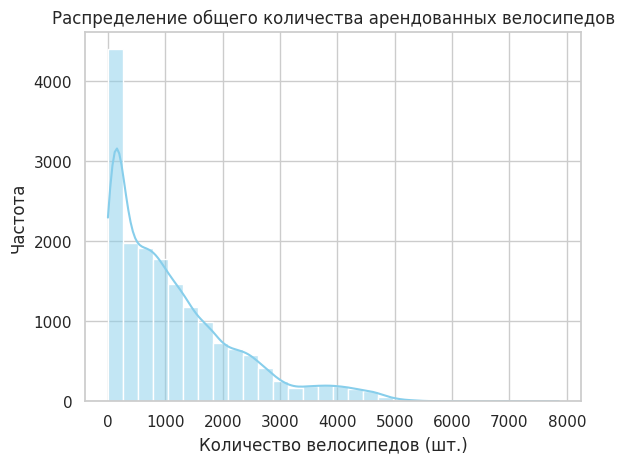

In [ ]:
sns.set_theme(style="whitegrid")

sns.histplot(bike['total_count'], bins=30, kde=True, color="skyblue")
plt.title("Распределение общего количества арендованных велосипедов")
plt.xlabel("Количество велосипедов (шт.)")
plt.ylabel("Частота")

plt.show()

**Вывод**

Гистограмма показывает распределение количества аренд велосипедов. Видна смещённость вправо. У распределения выраженная правосторонняя асимметрия — большинство значений приходится на малые значения с заметным пиком в области очень низких показателей. Это говорит о том, что чаще всего велосипеды арендуют в небольшом количестве, а случаи массового проката встречаются значительно реже.

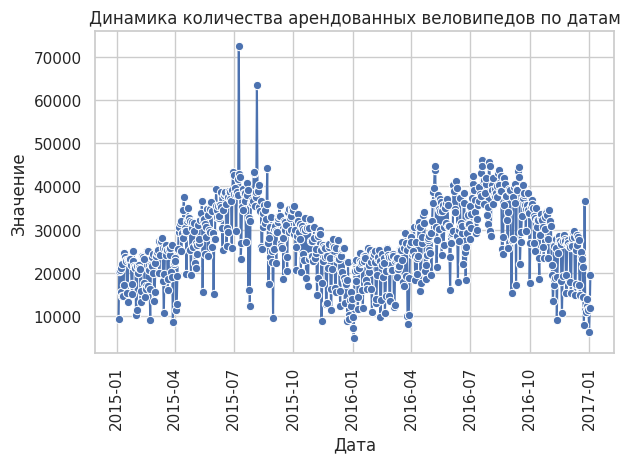

In [ ]:
bike['timestamp'] = pd.to_datetime(bike['timestamp']).dt.date

bide_date_tend = bike.groupby('timestamp')['total_count'].sum()

sns.set_theme(style='whitegrid')
sns.lineplot(x=bide_date_tend.index, y=bide_date_tend.values, marker='o')

plt.title("Динамика количества арендованных веловипедов по датам")
plt.xlabel("Дата")
plt.ylabel("Значение")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

## Задача 2 [3 балла]

Продолжи и построй более сложные графики.

###Задача 2.1 [1 балл]



1. Сгруппируй данные по столбцу `month` и посчитай суммарное количество аренд велосипедов по каждому месяцу.
2. Построй линейный график с зависимостью общего количества аренд от месяца.
3. Реализуй форматирование оси $Y$ так, чтобы значения отображались в тысячах.
4. Добавь подписи осей и заголовок графика.
5. Отобрази итоговый график.

Вывод здесь тоже уже написан.



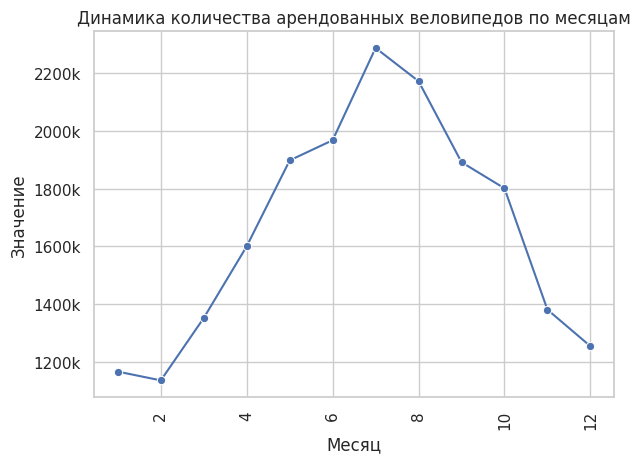

In [ ]:
import matplotlib.ticker as ticker

bike_month_tend = bike.groupby('month')['total_count'].sum()

sns.set_theme(style='whitegrid')
sns.lineplot(x=bike_month_tend.index, y=bike_month_tend.values, marker='o')

plt.title("Динамика количества арендованных веловипедов по месяцам")
plt.xlabel("Месяц")
plt.ylabel("Значение")
plt.xticks(rotation=90)

plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x/1000:.0f}k'))
plt.tight_layout()
plt.show()

**Вывод**

Данные показывают сезонные пики аренды велосипедов в летние месяцы (с июня по август) и спад в зимний период (с декабря по февраль). Количество аренд немного выросло с 2015 по 2016 год, но значительно снизилось в начале 2017 года. Это, вероятно, связано с внешними факторами или неполнотой данных. Использование системы велопроката зависит от тёплой погоды: летом спрос заметно выше.

###Задача 2.2 [1 балл]

1. Сгруппируй данные по сезонам и рассчитай для каждого сезона максимальное, минимальное и среднее количество аренд велосипедов с помощью функции `agg`.
2. Реализуй столбчатую диаграмму (`barplot`), которая показывает общее количество аренд велосипедов по сезонам.
3. Используй читаемые подписи сезонов вместо числовых значений (обрати внимание, как они закодированы в датасете).
4. Настрой размер графика (`figsize=(8, 4)`) и выбери цветовую палитру (`viridis`).
5. Добавь подписи осей `Season` и `Bike Shares` и заголовок графика `Total Bike Shares by Season`.
6. Отформатируй метки оси $Y$ так, чтобы значения были приведены в тысячах.
7. Выведи построенный график.

Вывод здесь уже написан.

In [ ]:
bike.groupby('season')['total_count'].agg(['min', 'max', 'mean'])

,min,max,mean
season,,,
0.0,0,5322,1103.831589
1.0,12,7860,1464.465238
2.0,9,5422,1178.954218
3.0,10,4415,821.729099


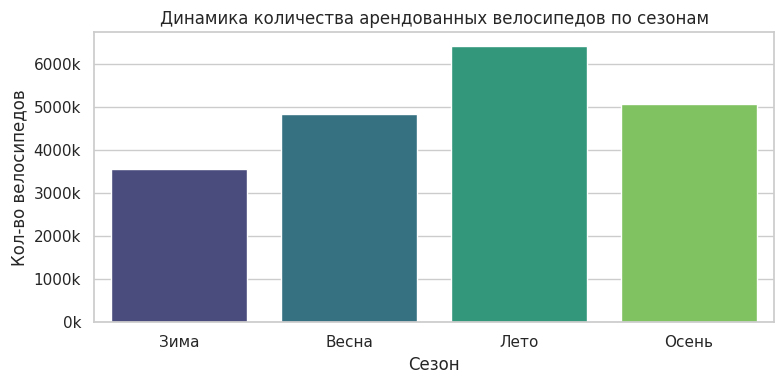

In [ ]:
season_map = {
    0.0: 'Весна',
    1.0: 'Лето',
    2.0: 'Осень',
    3.0: 'Зима'
}
bike['season_name'] = bike['season'].map(season_map)

season_order = ['Зима', 'Весна', 'Лето', 'Осень']
bike_season_tend = bike.groupby('season_name')['total_count'].sum().reindex(season_order)

plt.figure(figsize=(8, 4))
sns.barplot(x=bike_season_tend.index, y=bike_season_tend.values,
            order=season_order, palette='viridis')
plt.xlabel("Сезон")
plt.ylabel("Кол-во велосипедов")
plt.title("Динамика количества арендованных велосипедов по сезонам")
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x/1000:.0f}k'))
plt.tight_layout()
plt.show()

**Вывод**

Лето и осень лидируют по количеству арендованных велосипедов. Это подкрепляет нашу гипотезу о том, что благоприятные погодные условия влияют на количество аренд.

###Задача 2.3 [1 балл]

1. Сгруппируй датафрейм `bike` по признакам `season` и `day_of_week`. Вычисли среднее значение столбца `total_count` для каждой группы и сбрось индексы.
2. Построй `pointplot`, где по оси $X$ — `day_of_week`, по оси $Y$ — `total_count`. Цветом (`hue`) обозначь сезоны, заменив числовые коды на строковые метки (как и в задаче выше).
3. Задай подписи осей и заголовок графика.
4. Обнови подписи оси $X$ так, чтобы вместо чисел отображались названия дней недели.
5. Добавь легенду графика.
6. Используй `plt.tight_layout()` для корректного размещения элементов, а затем выведи график.

Дополнительно напиши вывод по полученному графику. Можешь использовать шаблон:

* пиковая нагрузка наблюдается ... особенно с ... по ...;
* на выходных отмечается ... по сравнению с рабочей неделей;
* на графике наблюдаются сезонные колебания, они ... нашу гипотезу, обозначенную выше;
* характер поведения данных ... во все сезоны.




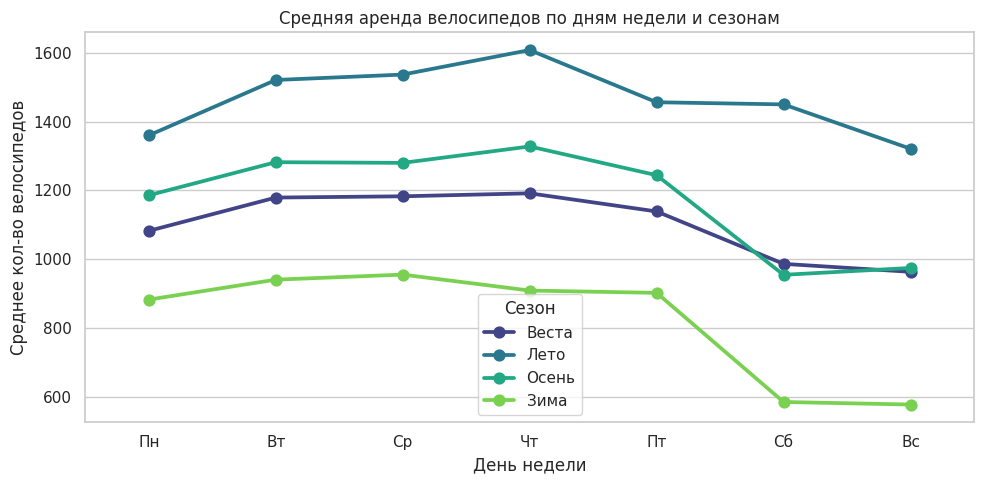

In [ ]:
season_map = {
    0.0: 'Веста',
    1.0: 'Лето',
    2.0: 'Осень',
    3.0: 'Зима'
}

day_map = {
    0: 'Пн',
    1: 'Вт',
    2: 'Ср',
    3: 'Чт',
    4: 'Пт',
    5: 'Сб',
    6: 'Вс'
}

bike_season_week_tend = bike.groupby(['season', 'day_of_week'])['total_count'].mean().reset_index()

bike_season_week_tend['season_name'] = bike_season_week_tend['season'].map(season_map)

plt.figure(figsize=(10, 5))
sns.pointplot(
    data=bike_season_week_tend,
    x='day_of_week',
    y='total_count',
    hue='season_name',
    palette='viridis'
)

plt.xlabel("День недели")
plt.ylabel("Среднее кол-во велосипедов")
plt.title("Средняя аренда велосипедов по дням недели и сезонам")

ticks = sorted(bike_season_week_tend['day_of_week'].unique())
plt.xticks(ticks=range(len(ticks)), labels=[day_map[t] for t in ticks])

plt.legend(title="Сезон")

plt.tight_layout()
plt.show()

**Твой вывод**

Пиковая нагрузка наблюдается летом особенно с понедельника по пятницу. На выходных отмечается спад по сравнению с рабочей неделей. На графике наблюдаются сезонные колебания, они подтверждают нашу гипотезу, обозначенную выше;
характер поведения данных схож во всех сезонах.

## Задача 3 [2 балла]

###Задача 3.1 [1 балл]

1. Построй линейный график, который показывает распределение количества поездок на велосипедах в зависимости от времени суток.
2. Используй признак `is_weekend` в качестве группирующего фактора, чтобы сравнить популярность велопроката в будние и выходные дни.
3. Настрой легенду так, чтобы линии были подписаны как `No` (будний день) и `Yes` (выходной день).
4. Добавь заголовок графика.
5. Отобрази график с использованием функции `plt.tight_layout()` для корректного размещения элементов.
6. Напиши вывод. Опиши наблюдения по утренним и вечерним пикам, разницу между рабочими днями и выходными.



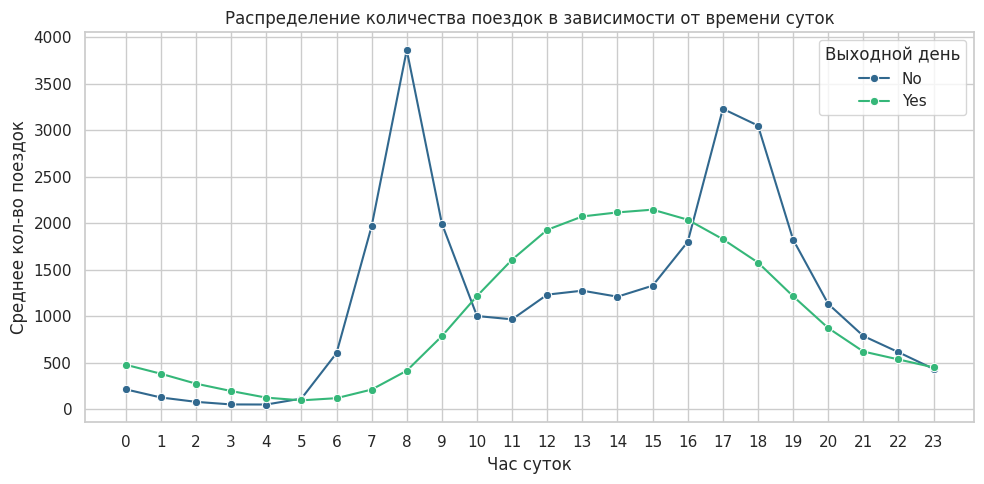

In [ ]:
bike_hour_tend = bike.groupby(['hour', 'is_weekend'])['total_count'].mean().reset_index()

plt.figure(figsize=(10, 5))
ax = sns.lineplot(
    data=bike_hour_tend,
    x='hour',
    y='total_count',
    hue='is_weekend',
    palette='viridis',
    marker='o'
)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=['No', 'Yes'],
          title="Выходной день")

plt.xlabel("Час суток")
plt.ylabel("Среднее кол-во поездок")

plt.title("Распределение количества поездок в зависимости от времени суток")

plt.xticks(range(0, 24))

plt.tight_layout()
plt.show()

**Твой вывод**

На графике чётко видны различия в поведении велопроката в будние и выходные дни.
В будние дни (No) наблюдаются два выраженных пика: утренний — около 8 часов утра, и вечерний — около 17–18 часов. Это соответствует времени поездок на работу и обратно, что говорит об использовании велосипедов преимущественно для ежедневных рабочих поездок.
В выходные дни (Yes) утренний и вечерний пики отсутствуют. Вместо этого активность плавно нарастает в течение дня и достигает максимума в дневное время (примерно с 12 до 16 часов). Это указывает на то, что в выходные велосипеды используются в основном для отдыха и прогулок.
В ночные и ранние утренние часы (примерно с 0 до 5) количество поездок минимально в оба типа дней. Таким образом, характер спроса на велопрокат существенно зависит от типа дня недели.

###Задача 3.2 [1 балл]
1. Создай график с двумя круговыми диаграммами, расположенными в одну строку.
2. Для первой диаграммы отобрази распределение количества поездок по признаку `is_holiday` с метками `No` и `Yes`. Укажи процентное соотношение каждого значения, используй цвета `lightblue` и `orange`. Установи начальный угол (`startangle`) на 90 градусов и добавь заголовок.
3. Для второй диаграммы отобрази распределение количества поездок по признаку `is_weekend` с метками `Weekday` и `Weekend`. Укажи процентное соотношение каждого значения, используй те же цвета и начальный угол, добавь заголовок.
4. Обеспечь компактное расположение графиков с помощью tight_layout.
5. Отобрази полученный график.
6. Опиши обе круговые диаграммы. Какие выводы  можно сделать по каждой из них?


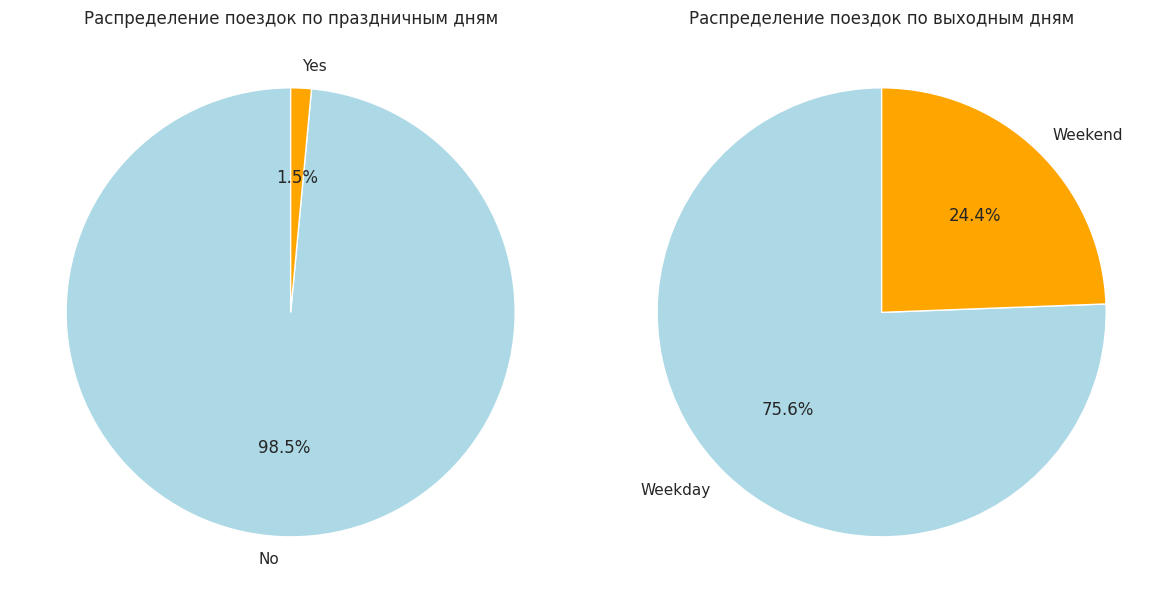

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

holiday_counts = bike.groupby('is_holiday')['total_count'].sum()
axes[0].pie(
    holiday_counts,
    labels=['No', 'Yes'],
    autopct='%1.1f%%',
    colors=['lightblue', 'orange'],
    startangle=90
)
axes[0].set_title("Распределение поездок по праздничным дням")

weekend_counts = bike.groupby('is_weekend')['total_count'].sum()
axes[1].pie(
    weekend_counts,
    labels=['Weekday', 'Weekend'],
    autopct='%1.1f%%',
    colors=['lightblue', 'orange'],
    startangle=90
)
axes[1].set_title("Распределение поездок по выходным дням")

plt.tight_layout()
plt.show()

**Твой вывод**

Обе круговые диаграммы показывают распределение общего количества поездок по типам дней.
Первая диаграмма (праздничные дни): подавляющее большинство поездок приходится на обычные (непраздничные) дни — категория No. Доля поездок в праздники (Yes) очень мала. Это объясняется тем, что праздничных дней в году значительно меньше, чем обычных, а также тем, что в праздники велосипеды реже используются для рабочих поездок.
Вторая диаграмма (выходные дни): большая часть поездок совершается в будние дни (Weekday), тогда как на выходные (Weekend) приходится меньшая доля. Это подтверждает, что велопрокат в первую очередь используется для регулярных поездок на работу и учёбу. Однако разница между будними и выходными днями здесь менее выражена, чем в случае с праздниками, поскольку выходных дней в неделе относительно больше (два из семи).
Общий вывод: спрос на велопрокат формируется преимущественно за счёт рабочих поездок в будние непраздничные дни.

## Задача 4 [3 балла]

###Задача 4.1 **[1 балл]**

1. Построй два `scatter plot` на одной фигуре с двумя строками и одним столбцом, `figsize=(15, 10)`.
2. На первом графике отобрази зависимость количества поездок на велосипедах (`total_count`) от температуры (`temp`). Обязательно добавь заголовки.
3. На втором графике отобрази зависимость количества поездок на велосипедах (`total_count`) от кода погоды (`weather_code`). Также обязательно добавь заголовки.
 * Добавь на ось $X$ второго графика метки с названиями погодных условий согласно описанию датасета.
 * Поверни подписи на 90 градусов, выровняй по центру, задай размер шрифта 10.
4. Обеспечь удобное расположение графиков с помощью `plt.tight_layout(pad=3.0)`.
5. В выводе напиши, какие закономерности ты видишь на каждом из графиков.


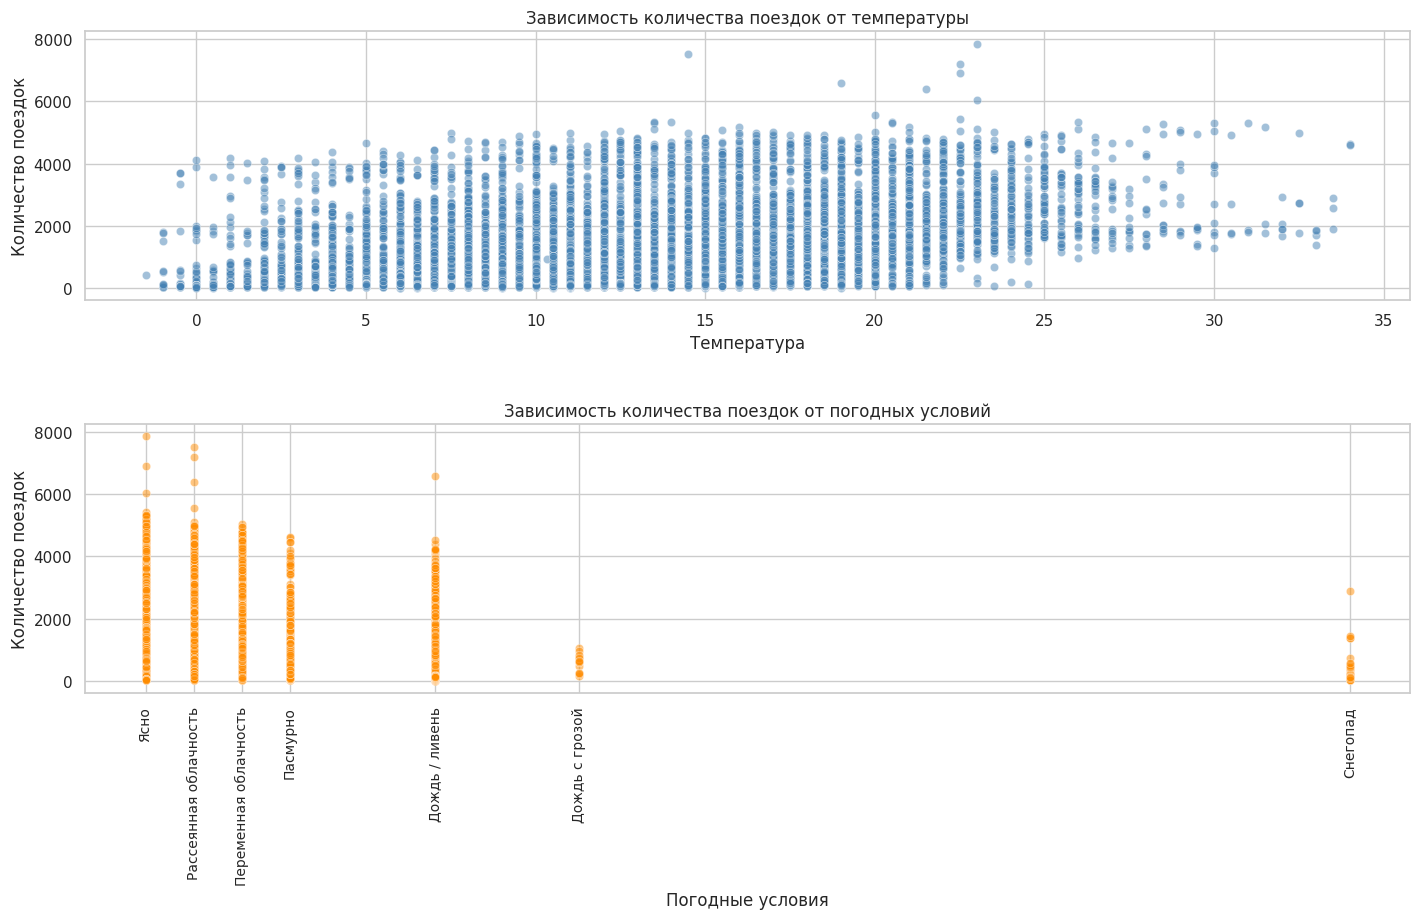

In [ ]:
weather_labels = {
    1: 'Ясно',
    2: 'Рассеянная облачность',
    3: 'Переменная облачность',
    4: 'Пасмурно',
    7: 'Дождь / ливень',
    10: 'Дождь с грозой',
    26: 'Снегопад',
    94: 'Туман'
}

fig, axes = plt.subplots(2, 1, figsize=(15, 10))

sns.scatterplot(
    data=bike,
    x='temp',
    y='total_count',
    ax=axes[0],
    color='steelblue',
    alpha=0.5
)
axes[0].set_title("Зависимость количества поездок от температуры")
axes[0].set_xlabel("Температура")
axes[0].set_ylabel("Количество поездок")

sns.scatterplot(
    data=bike,
    x='weather_code',
    y='total_count',
    ax=axes[1],
    color='darkorange',
    alpha=0.5
)
axes[1].set_title("Зависимость количества поездок от погодных условий")
axes[1].set_xlabel("Погодные условия")
axes[1].set_ylabel("Количество поездок")

codes = sorted(bike['weather_code'].dropna().unique())
axes[1].set_xticks(codes)
axes[1].set_xticklabels(
    [weather_labels.get(int(c), str(c)) for c in codes],
    rotation=90,
    ha='center',
    fontsize=10
)

plt.tight_layout(pad=3.0)
plt.show()

**Твой вывод**

На первом графике (зависимость от температуры) прослеживается положительная связь: с ростом температуры количество поездок в целом увеличивается. При низких температурах поездок мало, тогда как при умеренно тёплой и тёплой погоде наблюдается наибольшая активность. При очень высоких температурах активность может немного снижаться, но общая тенденция остаётся возрастающей. Это логично: комфортная тёплая погода стимулирует использование велосипедов.

На втором графике (зависимость от погодных условий) видно, что наибольшее количество поездок приходится на ясную погоду и лёгкую облачность (коды 1–2). По мере ухудшения погоды — при пасмурности, дожде, грозе и снегопаде — количество и максимальные значения поездок заметно снижаются. При неблагоприятных условиях (дождь с грозой, снегопад) поездок совсем мало. Стоит отметить, что для погодного условия «Туман» (код 94) на графике нет ни одной точки — в данных отсутствуют наблюдения с этим кодом, поэтому по нему нельзя сделать никаких выводов. Это подтверждает, что спрос на велопрокат сильно зависит от погоды: люди предпочитают ездить на велосипедах в хорошую, ясную погоду.

###Задача 4.2 [2 балла]

In [ ]:
# Прежде чем перейти к следующему шагу — немного подправь данные
# Cтандартизация через StandardScaler

from sklearn.preprocessing import StandardScaler

# Возьми только числовые признаки
numerical_features = bike[['total_count', 'temp', 'feel_temp', 'humidity', 'wind_speed']]

# Инициализируй скейлер
scaler = StandardScaler()

# Примени его к числовым признакам
df_scaled = scaler.fit_transform(numerical_features)

# Переведи результат обратно в DataFrame
df_scaled = pd.DataFrame(df_scaled, columns=['total_count', 'temp', 'feel_temp', 'humidity', 'wind_speed'])



Создай финальный график.

1. Сделай расчёт корреляционной матрицы для датафрейма `df_scaled`. Построй тепловую карту (`heatmap`) этой матрицы с отображением значений корреляций, используй цветовую палитру `coolwarm`. Добавь заголовок и отобрази график.

2. Напиши подробный вывод по получившейся матрице. В первую очередь нас интересует, с чем коррелирует целевая переменная `total_count` и наибольшие значения положительной и отрицательной корреляции в матрице. Напиши минимум три пункта, которые вызывают интерес и могут быть полезны для решения задачи.



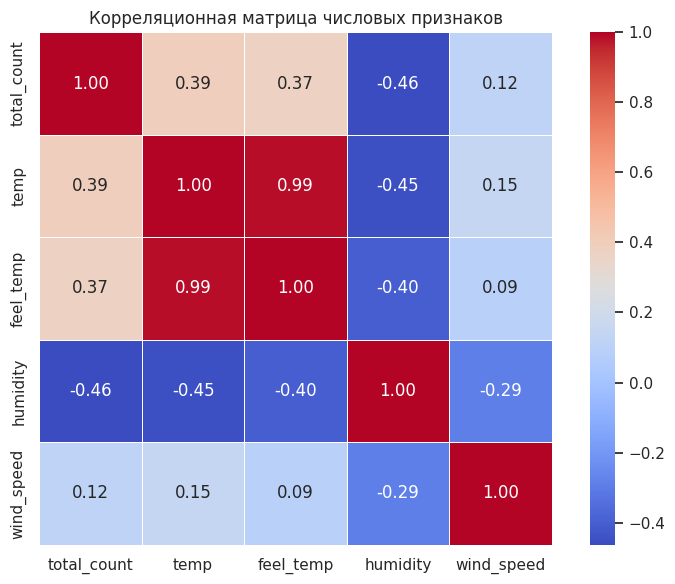

In [ ]:
corr_matrix = df_scaled.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    square=True
)
plt.title("Корреляционная матрица числовых признаков")
plt.tight_layout()
plt.show()

**Твой вывод**

По полученной корреляционной матрице можно выделить несколько важных наблюдений:

1. Целевая переменная total_count наиболее сильно и положительно коррелирует с температурой (temp) и ощущаемой температурой (feel_temp). Это означает, что чем теплее на улице, тем больше поездок совершается. Эти признаки являются наиболее перспективными для прогнозирования спроса на велопрокат.

2. Самая сильная положительная корреляция во всей матрице наблюдается между temp и feel_temp (0.99). Это логично, поскольку реальная и ощущаемая температура тесно связаны. Такая мультиколлинеарность означает, что для модели, вероятно, достаточно оставить только один из этих признаков, чтобы избежать дублирования информации.

3. Целевая переменная total_count имеет отрицательную корреляцию с влажностью (humidity): при высокой влажности количество поездок снижается. Это соответствует здравому смыслу — в сырую и дождливую погоду люди реже пользуются велосипедами.

4. Признак wind_speed слабо коррелирует с total_count: сильный ветер немного снижает число поездок, но влияние этого фактора выражено значительно слабее, чем у температуры и влажности. Такой признак может оказаться менее значимым для модели.

Общий вывод: наибольшую прогностическую ценность для предсказания total_count представляют температурные признаки (положительная связь) и влажность (отрицательная связь). При этом из-за сильной корреляции между temp и feel_temp один из них можно исключить для упрощения модели и борьбы с мультиколлинеарностью.

## Задача 5 [3 балла]

В задаче 5 ты полностью подготовишь данные для подачи в модель: выполнишь нормализацию признаков и разделишь данные на обучающую и тестовую выборки.  

1. Обучи любую модель регрессии из библиотеки `scikit-learn`.
2. Реализуй собственные функции для расчёта коэффициента детерминации (R²) и среднеквадратичной ошибки (MSE). **[1 балл]**
3. Вычисли значения метрик с помощью своих функций и сравни их с результатами расчёта с использованием функций из `scikit-learn` (должны получиться одинаковыми).
4. Составь краткий вывод по метрикам: какие значения получились и как их можно интерпретировать с точки зрения качества модели. **[2 балла]**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
X = bike.drop(['total_count','timestamp'], axis=1)
y = bike['total_count']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = pd.concat(
    [
        pd.DataFrame(
            scaler.fit_transform(X_train[['temp', 'feel_temp', 'humidity', 'wind_speed']]),
            columns=['temp', 'feel_temp', 'humidity', 'wind_speed']
        ).reset_index(drop=True),
        X_train[['weather_code', 'is_holiday', 'is_weekend', 'season', 'year', 'month','day','day_of_week','hour']].reset_index(drop=True)
    ],
    axis=1
)
X_test_scaled = pd.concat(
    [
        pd.DataFrame(
            scaler.fit_transform(X_test[['temp', 'feel_temp', 'humidity', 'wind_speed']]),
            columns=['temp', 'feel_temp', 'humidity', 'wind_speed']
        ).reset_index(drop=True),
        X_test[['weather_code', 'is_holiday', 'is_weekend', 'season', 'year', 'month','day','day_of_week','hour']].reset_index(drop=True)
    ],
    axis=1
)

In [ ]:
def r2(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    SSres = 0
    SStot = 0
    mean = np.mean(y_true)

    for i in range(len(y_true)):
        SSres += (y_true[i] - y_pred[i])**2
        SStot += (y_true[i] - mean)**2

    return 1 - (SSres / SStot)

In [ ]:
def mse(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    return sum((y_true - y_pred)**2)/len(y_pred)

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

np.float64(1142.8490799974434)

In [ ]:
print(r2(y_test, y_pred))
print(r2_score(y_test, y_pred))

0.2897129949682772
0.2897129949682785


In [ ]:
print(mse(y_test, y_pred))
print(mean_squared_error(y_test, y_pred))

851096.4127254908
851096.4127254899


**Твой вывод**

Результаты, полученные с помощью собственных функций, практически полностью совпадают со значениями из scikit-learn:

- R²: 0.2897129949682772 (собственная функция) и 0.2897129949682785 (scikit-learn)
- MSE: 851096.4127254908 (собственная функция) и 851096.4127254899 (scikit-learn)

Расхождения наблюдаются лишь в последних знаках после запятой и вызваны особенностями машинной арифметики с плавающей точкой (порядок суммирования, округления). Практически это одни и те же значения, что подтверждает корректность ручной реализации метрик.

Интерпретация метрик:

1. Коэффициент детерминации R² ≈ 0.29 означает, что модель объясняет лишь около 29% разброса целевой переменной total_count. Это довольно низкий показатель: большая часть вариации спроса на велосипеды остаётся необъяснённой. Линейная регрессия слабо описывает данные, а значит, зависимость между признаками и целевой переменной, вероятно, нелинейна.

2. Среднеквадратичная ошибка MSE ≈ 851096 измеряется в квадрате единиц целевой переменной. Для более наглядной интерпретации можно взять корень (RMSE ≈ 923), что уже выражается в тех же единицах, что и количество поездок. Это означает, что типичная ошибка прогноза модели составляет порядка нескольких сотен поездок — довольно много, что также говорит о невысоком качестве.